# Notebook 03: Machine Learning supervisé

> **Dans quelle mesure la structure du réseau TGV est-elle associée à la régularité des liaisons, et peut-on exploiter cette structure pour améliorer la prédiction des retards ?**

Dans ce notebook nous cherchons à prédire le taux de trains TGV arrivant avec plus de 15 minutes de retard, pour une liaison et un mois donné. Pour cela nous utiliserons les données qui font suite à notre ETL (`data/processed/sncf.parquet`).

Par exemple, pour la liaison Paris Lyon en septembre, nous voulons prédire le pourcentage de trains qui seront en retard à partir des informations disponibles les mois précédents.

Pour cela, nous allons comparer deux approches :
- Un modèle naïf, qui utilise simplement les retards historiques.
- Un modèle HistGradientBoosting, qui apprend des relations plus complexes à partir de plusieurs variables.

Nous devons ensuite mesurer la qualité de leurs prédictions. C'est pourquoi nous utilisons trois métriques : MAE, RMSE et MAE pondérée.


## I. Chargement des données ETL

In [61]:

"""Chargement des données ETL pour le Machine Learning supervisé."""

from pathlib import Path
import sys

import pandas as pd

# Récupérer le dossier dans lequel le notebook est exécuté.
project_root = Path.cwd()

# Si on se trouve dans notebooks/, remonter à la racine du projet.
if project_root.name == "notebooks":
    project_root = project_root.parent

# Ajouter src/ pour pouvoir importer les fonctions du projet.
sys.path.insert(0, str(project_root / "src"))

# Importer les fonctions nécessaires à la préparation des données,
# à l'entraînement des modèles et à leur évaluation.
from projet_kit_data.ml.baseline import (
    BASELINE_FEATURES,          # Liste de toutes les variables utilisées par le modèle.
    BASELINE_NUMERIC_FEATURES,  # Liste des variables numériques à préparer.
    build_baseline_dataset,     # Crée les variables historiques à partir des mois précédents.
    chronological_split,        # Sépare les données en entraînement, validation et test par date.
    predict_historical_naive,   # Prédit les retards à partir des taux historiques des liaisons.
    prepare_baseline_data,      # Adapte les données ETL et calcule la variable cible.
)

from projet_kit_data.ml.evaluation import compute_metrics
from projet_kit_data.ml.models import build_model

# indique ou se trouve le fichier préparé par l'ETL
etl_path = project_root / "data" / "processed" / "sncf.parquet"

# verifier que le fichier existe avant de le charger.
if not etl_path.is_file():
    raise FileNotFoundError(f"Données ETL introuvables : {etl_path}")

# charger les données dans un DataFrame pandas.
data_etl = pd.read_parquet(etl_path)

# quelques verifs
print("Dimensions ETL :", data_etl.shape)
print("Périodes :", data_etl["date"].min(), "→", data_etl["date"].max())

display(data_etl.head(3))


Dimensions ETL : (12907, 30)
Périodes : 2018-01 → 2026-09


,date,service,gare_depart,gare_arrivee,duree_moyenne,nb_train_prevu,nb_annulation,commentaire_annulation,nb_train_depart_retard,retard_moyen_depart,...,prct_cause_externe,prct_cause_infra,prct_cause_gestion_trafic,prct_cause_materiel_roulant,prct_cause_gestion_gare,prct_cause_prise_en_charge_voyageurs,flag_negative_count,flag_sup30_lt_sup60,flag_sup15_lt_sup30,flag_cancellations_gt_planned
0,2018-01,National,BORDEAUX ST JEAN,PARIS MONTPARNASSE,141,870,5,NaN,289,11.247809,...,36.134454,31.092437,10.924370,15.966387,5.042017,0.840336,False,False,False,False
1,2018-01,National,LE MANS,PARIS MONTPARNASSE,56,406,1,NaN,213,8.479969,...,20.000000,35.000000,16.666667,16.666667,8.333333,3.333333,False,False,False,False
2,2018-01,National,PARIS MONTPARNASSE,LA ROCHELLE VILLE,166,226,0,NaN,21,6.239683,...,22.222222,27.777778,16.666667,16.666667,5.555556,11.111111,False,False,False,False


## II. Définition de la cible et contrôles de validité

La cible est définie par :


$\text{delay\_rate\_15} = \frac{\text{nb\_train\_retard\_sup\_15}}{\text{nb\_train\_prevu} - \text{nb\_annulation}}$

Nous vérifions les compteurs, un dénominateur strictement positif et un numérateur compris entre 0 et ce dénominateur. Aucune suppression ni correction n'est appliquée à `data_etl`.


In [62]:
data_ml = prepare_baseline_data(data_etl)
print("Observations totales:", len(data_ml))
print("Cibles valides :", int(data_ml["valid_target"].sum()))
print("Cibles invalides :", int((~data_ml["valid_target"]).sum()))
print("Doublons sur la clé métier :", int(data_ml.duplicated(
    ["date", "service", "departure", "arrival"]
).sum()))
display(data_ml[["date", "service", "departure", "arrival", "circulated", "delay_rate_15", "valid_target"]].head())


Observations totales: 12907
Cibles valides : 12832
Cibles invalides : 75
Doublons sur la clé métier : 0


,date,service,departure,arrival,circulated,delay_rate_15,valid_target
0,2018-01-01,International,BARCELONA,PARIS LYON,35,0.200000,True
1,2018-01-01,International,FRANCFORT,PARIS EST,174,0.143678,True
2,2018-01-01,International,GENEVE,PARIS LYON,229,0.157205,True
3,2018-01-01,International,ITALIE,PARIS LYON,94,0.361702,True
4,2018-01-01,International,LAUSANNE,PARIS LYON,141,0.156028,True


## III. Construction des variables historiques

Les taux de retard, volumes et nombres d'observations **historiques** sont regroupés par `(service, departure, arrival)`. Les observations du mois *t* sont exclues de ces agrégations.


In [63]:

# Utiliser les 12 mois précédents pour construire l'historique.
historical_window = 12

# Créer le dataset avec les variables historiques des liaisons.
dataset = build_baseline_dataset(
    data_ml,
    window_months=historical_window,
)

# Vérifier les dimensions après la création de l'historique.
print("Dimensions après historique :", dataset.shape)

# Afficher la période sur laquelle nous pouvons faire des prédictions.
print(
    "Période prédictive :",
    dataset["date"].min().date(),
    "→",
    dataset["date"].max().date(),
)

# Afficher les variables utilisées pour entraîner notre modèle.
print("Variables explicatives :", BASELINE_FEATURES)

# Calculer le pourcentage d'observations sans historique
# disponible pour leur liaison.
print(
    "Taux de données sans historique de liaison :",
    round(
        dataset["historical_delay_rate_15"].isna().mean() * 100,
        2,
    ),
    "%",
)

# Afficher les premières observations avec leurs variables
# explicatives, leur taux de retard et la validité de la cible.
display(
    dataset[
        ["date", *BASELINE_FEATURES, "delay_rate_15", "valid_target"]
    ].head(5)
)


Dimensions après historique : (11347, 14)
Période prédictive : 2019-01-01 → 2026-09-01
Variables explicatives : ['service', 'departure', 'arrival', 'month', 'historical_delay_rate_15', 'historical_circulated', 'historical_observations']
Taux de données sans historique de liaison : 0.17 %


,date,service,departure,arrival,month,historical_delay_rate_15,historical_circulated,historical_observations,delay_rate_15,valid_target
0,2019-01-01,International,BARCELONA,PARIS LYON,1,0.224566,806.0,12.0,0.096774,True
1,2019-01-01,International,FRANCFORT,PARIS EST,1,0.191141,1648.0,12.0,0.267081,True
2,2019-01-01,International,GENEVE,PARIS LYON,1,0.161439,2391.0,12.0,0.082609,True
3,2019-01-01,International,ITALIE,PARIS LYON,1,0.386089,992.0,12.0,0.223404,True
4,2019-01-01,International,LAUSANNE,PARIS LYON,1,0.134309,1571.0,12.0,0.070922,True


## IV. Séparation chronologique

La même liaison peut figurer dans plusieurs mois, mais **aucun mois n'est partagé entre les trois jeux**. Les taux réels du mois courant ne figurent jamais parmi les variables explicatives.


In [64]:

# Séparer les données chronologiquement :
# 70 % pour l'entraînement, 15 % pour la validation
# et les 15 % restants pour le test.
train, validation, test = chronological_split(
    dataset,
    train_fraction=0.70,
    validation_fraction=0.15,
)

# Afficher le nombre d'observations et la période
# couverte par chaque ensemble.
for nom, frame in (
    ("Train", train),
    ("Validation", validation),
    ("Test", test),
):
    print(
        f"{nom} : {len(frame)} lignes, "
        f"du {frame['date'].min().date()} "
        f"au {frame['date'].max().date()}"
    )

# Vérifier que les périodes ne se chevauchent pas.
# Les données de validation doivent être postérieures
# à celles d'entraînement, et celles de test à la validation.
assert train["date"].max() < validation["date"].min()
assert validation["date"].max() < test["date"].min()


Train : 7844 lignes, du 2019-01-01 au 2024-05-01
Validation : 1571 lignes, du 2024-06-01 au 2025-06-01
Test : 1857 lignes, du 2025-07-01 au 2026-09-01


## V. Modèles : référence naïve et modèle supervisé

- **Baseline naïve :** taux des 12 mois précédents pour la même liaison et le même service et en l'absence d'historique, taux global du jeu d'entraînement.
- **HistGradientBoostingRegressor :** même objectif, à partir des catégories de liaison, du mois et des variables historiques.

Les paramètres sont fixés avant l'évaluation finale. Nous n'utilisons pas le test pour sélectionner le modèle. Les prédictions de régression sont bornées à `[0, 1]` pour respecter l'échelle du taux.


In [65]:

# Faire les premières prédictions sur la validation
# avec notre modèle naïf basé sur l'historique des retards.
naive_validation = predict_historical_naive(train, validation)

# Construire notre modèle HistGradientBoosting.
# max_iter : nombre maximal d'itérations d'apprentissage.
# learning_rate : vitesse à laquelle le modèle apprend.
# max_leaf_nodes : nombre maximal de feuilles par arbre.
model = build_model(
    numeric_features=BASELINE_NUMERIC_FEATURES,
    max_iter=150,
    learning_rate=0.05,
    max_leaf_nodes=15,
)

# Entraîner le modèle avec les données d'entraînement.
# Le nombre de trains ayant circulé sert de poids :
# les observations avec plus de trains ont davantage d'importance.
model.fit(
    train[BASELINE_FEATURES],
    train["delay_rate_15"],
    regressor__sample_weight=train["circulated"],
)

# Prédire les taux de retard sur les données de validation.
# clip(0, 1) limite les prédictions entre 0 % et 100 %.
model_validation = model.predict(
    validation[BASELINE_FEATURES]
).clip(0, 1)

# Calculer les métriques des deux modèles :
# MAE, RMSE et MAE pondérée par le nombre de trains.
validation_results = pd.DataFrame([
    {
        "modele": "Naïf historique",
        **compute_metrics(
            validation["delay_rate_15"],
            naive_validation,
            validation["circulated"],
        ),
    },
    {
        "modele": "HistGradientBoosting",
        **compute_metrics(
            validation["delay_rate_15"],
            model_validation,
            validation["circulated"],
        ),
    },
]).set_index("modele")

# Afficher les résultats pour comparer les deux modèles.
display(validation_results)


,mae,rmse,weighted_mae
modele,,,
Naïf historique,0.030271,0.044299,0.025791
HistGradientBoosting,0.030212,0.044181,0.025321



### Comparaison des modèles sur le jeu de validation

Pour comparer notre modèle naïf et HistGradientBoosting, nous utilisons trois métriques : la **MAE**, la **RMSE** et la **MAE pondérée**.

**MAE : Mean Absolute Error**

La MAE mesure l'erreur moyenne entre les taux de retard réels et les prédictions.

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i-\hat{y}_i|$$

**RMSE : Root Mean Squared Error**

La RMSE mesure également les erreurs, mais pénalise davantage les prédictions qui s'éloignent fortement des valeurs réelles.

$$
RMSE = \sqrt{\frac{1}{n}\sum_{i=1}^{n}(y_i-\hat{y}_i)^2}
$$

**MAE pondérée : Weighted Mean Absolute Error**

La MAE pondérée tient compte du nombre de trains ayant circulé. Les observations avec un trafic plus important ont donc davantage de poids.

$$
MAE_{\text{pondérée}} =\frac{\sum_{i=1}^{n}w_i|y_i-\hat{y}_i|}{\sum_{i=1}^{n}w_i}$$

Avec :
- $y_i$ : taux de retard réel ;
- $\hat{y}_i$ : taux de retard prédit ;
- $n$ : nombre d'observations ;
- $w_i$ : nombre de trains ayant circulé.

**Pour les trois métriques, plus la valeur est faible, meilleure est la prédiction.**


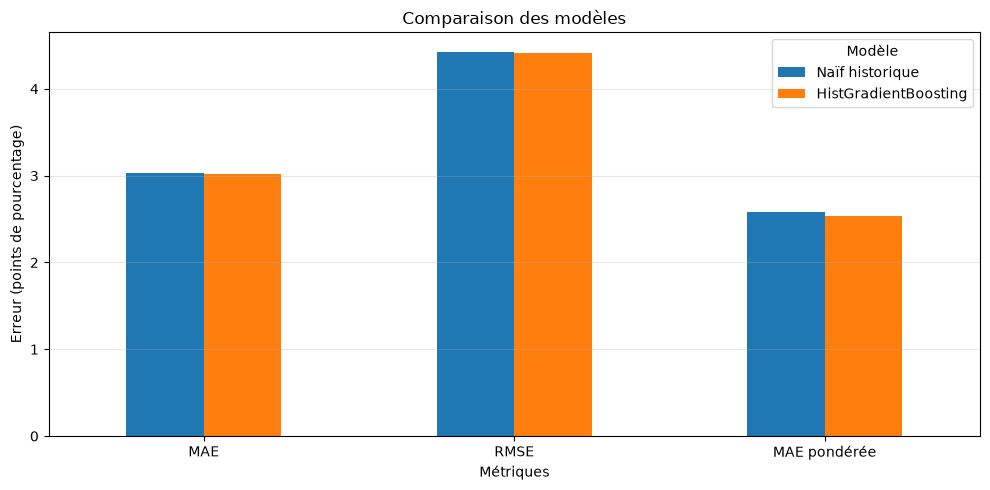

In [66]:

import matplotlib.pyplot as plt

# Passer les métriques en points de pourcentage
# pour faciliter la lecture du graphique.
metrics_plot = validation_results[
    ["mae", "rmse", "weighted_mae"]
].copy() * 100

# Renommer les colonnes pour l'affichage.
metrics_plot = metrics_plot.rename(
    columns={
        "mae": "MAE",
        "rmse": "RMSE",
        "weighted_mae": "MAE pondérée",
    }
)

# Comparer les erreurs des deux modèles.
ax = metrics_plot.T.plot(
    kind="bar",
    figsize=(10, 5),
    rot=0,
)

ax.set_title("Comparaison des modèles")
ax.set_xlabel("Métriques")
ax.set_ylabel("Erreur (points de pourcentage)")
ax.legend(title="Modèle")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()



#### Interprétation des résultats sur la validation

On constate que les deux modèles obtiennent des performances très proches. Le modèle HistGradientBoosting présente des erreurs légèrement plus faibles sur les trois métriques, avec une MAE de 3,02 points contre 3,03 pour le modèle naïf.

La MAE pondérée passe également de 2,58 à 2,53 points, ce qui montre une petite amélioration lorsqu'on prend en compte le nombre de trains ayant circulé.

Cependant, les différences restent faibles. **Le modèle supervisé ne semble donc pas apporter de gain important par rapport à une simple prédiction basée sur l'historique des retards.** Il faudra vérifier si cette tendance se confirme sur le jeu de test.

| Métrique | Naïf historique | HistGradientBoosting |
| :--- | :---: | :---: |
| MAE | 3,03 pts | 3,02 pts |
| RMSE | 4,43 pts | 4,42 pts |
| MAE pondérée | 2,58 pts | 2,53 pts |


Regardons les liaisons avec la plus grand taux d'erreur de prédiction

In [67]:

# Construire un tableau pour comparer les valeurs réelles
# et les prédictions sur le jeu de validation.
erreurs_validation = validation[
    [
        "date",
        "service",
        "departure",
        "arrival",
        "circulated",
        "delay_rate_15",
    ]
].copy()

# Ajouter les prédictions des deux modèles.
erreurs_validation["prediction_naive"] = naive_validation
erreurs_validation["prediction_ml"] = model_validation

# Calculer les erreurs absolues de chaque modèle.
erreurs_validation["erreur_naive"] = (
    erreurs_validation["delay_rate_15"]
    - erreurs_validation["prediction_naive"]
).abs()

erreurs_validation["erreur_ml"] = (
    erreurs_validation["delay_rate_15"]
    - erreurs_validation["prediction_ml"]
).abs()

# Identifier les observations les plus difficiles à prédire.
display(
    erreurs_validation.sort_values(
        "erreur_ml",
        ascending=False,
    ).head(15)
)


,date,service,departure,arrival,circulated,delay_rate_15,prediction_naive,prediction_ml,erreur_naive,erreur_ml
9375,2025-06-01,International,PARIS EST,STUTTGART,101,0.732673,0.212963,0.250977,0.519710,0.481696
9298,2025-05-01,National,MARSEILLE ST CHARLES,TOURCOING,6,0.500000,0.181556,0.162465,0.318444,0.337535
9253,2025-05-01,International,PARIS EST,FRANCFORT,174,0.396552,0.152704,0.143216,0.243848,0.253336
9254,2025-05-01,International,PARIS EST,STUTTGART,88,0.431818,0.193734,0.179681,0.238084,0.252137
8041,2024-07-01,International,ITALIE,PARIS LYON,26,0.538462,0.251572,0.322479,0.286889,0.215982
9374,2025-06-01,International,PARIS EST,FRANCFORT,164,0.420732,0.171076,0.213849,0.249656,0.206883
8632,2024-11-01,National,SAINT ETIENNE CHATEAUCREUX,PARIS LYON,51,0.274510,0.073380,0.083611,0.201130,0.190899
8984,2025-02-01,National,PARIS MONTPARNASSE,VANNES,222,0.238739,0.100726,0.070775,0.138013,0.167964
8164,2024-08-01,International,PARIS EST,FRANCFORT,95,0.063158,0.200554,0.229355,0.137396,0.166197
7925,2024-06-01,International,PARIS LYON,BARCELONA,70,0.000000,0.122581,0.165859,0.122581,0.165859



#### Analyse des erreurs sur la validation

On remarque que les erreurs les plus importantes concernent principalement des liaisons présentant des taux de retard élevés, notamment certaines liaisons internationales.

Par exemple, sur Paris Est Stuttgart en juin 2025, le taux réel atteint 73,27 %, contre seulement 25,10 % prédit par HistGradientBoosting. Le modèle semble donc avoir des difficultés à anticiper certaines fortes variations de régularité.

On observe également que certaines erreurs concernent des liaisons avec peu de trains, ce qui peut rendre les taux de retard plus variables.

Ces résultats montrent les limites de notre modèle actuel. Nous allons maintenant vérifier si les erreurs sont particulièrement importantes selon le service et le volume de circulation, avant de chercher à améliorer les paramètres.


In [68]:

# Comparer les erreurs du modèle selon le service.
# La MAE mesure l'erreur moyenne par observation.
# La MAE pondérée tient compte du volume de trains.

resultats_services = []

for service, groupe in erreurs_validation.groupby("service"):
    metriques = compute_metrics(
        groupe["delay_rate_15"],
        groupe["prediction_ml"],
        groupe["circulated"],
    )

    resultats_services.append(
        {
            "service": service,
            "observations": len(groupe),
            "nombre_trains": groupe["circulated"].sum(),
            "mae": metriques["mae"],
            "rmse": metriques["rmse"],
            "mae_ponderee": metriques["weighted_mae"],
        }
    )

# Afficher les erreurs en points de pourcentage.
comparaison_services = pd.DataFrame(resultats_services)

colonnes_metriques = ["mae", "rmse", "mae_ponderee"]
comparaison_services[colonnes_metriques] *= 100

display(comparaison_services.round(2))


,service,observations,nombre_trains,mae,rmse,mae_ponderee
0,International,180,22890,5.5,7.98,4.75
1,National,1391,451336,2.7,3.71,2.42



#### Comparaison des erreurs par service

On constate que le modèle prédit moins bien les retards des liaisons internationales, avec une MAE de **5,50 points contre 2,70 pour les liaisons nationales**. La RMSE est également plus élevée (7,98 contre 3,71 points), ce qui montre que les erreurs importantes sont davantage présentes à l'international.

Cette différence peut notamment être liée au nombre plus faible d'observations internationales et aux fortes variations de régularité sur certaines liaisons.

La MAE pondérée confirme cette tendance, avec 4,75 points pour l'international contre 2,42 pour le national.

Ces résultats montrent que **notre modèle est plus précis sur les liaisons nationales**, mais qu'il reste des améliorations possibles pour mieux prendre en compte les particularités des liaisons internationales.



### Recherche des meilleurs hyperparamètres

Les premiers résultats montrent que HistGradientBoosting améliore légèrement les prédictions par rapport au modèle naïf, mais que certaines erreurs restent importantes.

Nous allons maintenant tester plusieurs configurations du modèle en faisant varier le nombre d'itérations, la vitesse d'apprentissage et la complexité des arbres.

Chaque modèle sera entraîné sur les mêmes données, puis évalué sur le jeu de validation avec les trois métriques : **MAE, RMSE et MAE pondérée**.

Nous retiendrons la configuration présentant la meilleure MAE pondérée, tout en surveillant les autres métriques.

Le jeu de test reste volontairement inutilisé à cette étape.


In [69]:

# Définir les configurations que nous souhaitons comparer.
configurations = [
    {
        "nom": "Actuel",
        "max_iter": 150,
        "learning_rate": 0.05,
        "max_leaf_nodes": 15,
    },
    {
        "nom": "Simple",
        "max_iter": 100,
        "learning_rate": 0.05,
        "max_leaf_nodes": 10,
    },
    {
        "nom": "Plus long",
        "max_iter": 250,
        "learning_rate": 0.05,
        "max_leaf_nodes": 15,
    },
    {
        "nom": "Plus lent",
        "max_iter": 250,
        "learning_rate": 0.03,
        "max_leaf_nodes": 15,
    },
    {
        "nom": "Plus complexe",
        "max_iter": 200,
        "learning_rate": 0.10,
        "max_leaf_nodes": 31,
    },
]

# Tableau dans lequel nous stockerons les résultats.
resultats_configurations = []

# Entraîner un modèle différent pour chaque configuration.
for config in configurations:

    # Construire le modèle avec les paramètres choisis.
    modele = build_model(
        numeric_features=BASELINE_NUMERIC_FEATURES,
        max_iter=config["max_iter"],
        learning_rate=config["learning_rate"],
        max_leaf_nodes=config["max_leaf_nodes"],
    )

    # Entraîner le modèle sur le jeu d'entraînement uniquement.
    modele.fit(
        train[BASELINE_FEATURES],
        train["delay_rate_15"],
        regressor__sample_weight=train["circulated"],
    )

    # Prédire les taux de retard sur la validation.
    predictions = modele.predict(
        validation[BASELINE_FEATURES]
    ).clip(0, 1)

    # Calculer les trois métriques d'évaluation.
    metriques = compute_metrics(
        validation["delay_rate_15"],
        predictions,
        validation["circulated"],
    )

    # Conserver les paramètres et les résultats du modèle.
    resultats_configurations.append(
        {
            "configuration": config["nom"],
            "max_iter": config["max_iter"],
            "learning_rate": config["learning_rate"],
            "max_leaf_nodes": config["max_leaf_nodes"],
            **metriques,
        }
    )

# Regrouper les résultats dans un DataFrame.
comparaison_configurations = pd.DataFrame(
    resultats_configurations
)

# Trier les modèles selon la MAE pondérée.
comparaison_configurations = (
    comparaison_configurations
    .sort_values("weighted_mae")
    .reset_index(drop=True)
)

# Afficher les résultats.
display(comparaison_configurations.round(5))


,configuration,max_iter,learning_rate,max_leaf_nodes,mae,rmse,weighted_mae
0,Simple,100,0.05,10,0.02960,0.04347,0.02478
1,Plus lent,250,0.03,15,0.03016,0.04407,0.02528
2,Actuel,150,0.05,15,0.03021,0.04418,0.02532
3,Plus long,250,0.05,15,0.03048,0.04445,0.02557
4,Plus complexe,200,0.10,31,0.03177,0.04637,0.02692



#### Interprétation des tests d'hyperparamètres

Parmi les cinq configurations testées, le modèle **Simple** obtient les meilleurs résultats sur les trois métriques.

Avec 100 itérations, un taux d'apprentissage de 0,05 et 10 feuilles maximum par arbre, il atteint une MAE de 2,96 points et une MAE pondérée de 2,48 points.

À l'inverse, la configuration la plus complexe présente les erreurs les plus élevées. Augmenter le nombre d'itérations ou la complexité des arbres ne semble donc pas améliorer les performances dans notre cas.

Nous retenons la configuration **Simple** pour l'évaluation finale. Il reste à vérifier si ses performances se maintiennent sur le jeu de test.



### Entraînement du modèle final

Après comparaison des différentes configurations sur la validation, nous retenons le modèle Simple, qui présente les erreurs les plus faibles.

Nous allons maintenant réentraîner cette configuration sur l'ensemble des données d'entraînement et de validation.

Le jeu de test reste exclu de l'entraînement. Il servira uniquement à mesurer les performances finales sur des observations plus récentes.


In [70]:

# Regrouper les données d'entraînement et de validation.
train_final = pd.concat(
    [train, validation],
    ignore_index=True,
)

# Construire le modèle avec les paramètres retenus.
modele_final = build_model(
    numeric_features=BASELINE_NUMERIC_FEATURES,
    max_iter=100,
    learning_rate=0.05,
    max_leaf_nodes=10,
)

# Réentraîner le modèle sur toutes les données disponibles
# avant la période de test.
modele_final.fit(
    train_final[BASELINE_FEATURES],
    train_final["delay_rate_15"],
    regressor__sample_weight=train_final["circulated"],
)

# Vérifier les périodes utilisées.
print("Observations pour l'entraînement final :", len(train_final))
print(
    "Période d'entraînement :",
    train_final["date"].min().date(),
    "→",
    train_final["date"].max().date(),
)
print(
    "Période de test :",
    test["date"].min().date(),
    "→",
    test["date"].max().date(),
)

# Vérifier que le test commence après l'entraînement.
assert train_final["date"].max() < test["date"].min()


Observations pour l'entraînement final : 9415
Période d'entraînement : 2019-01-01 → 2025-06-01
Période de test : 2025-07-01 → 2026-09-01



### Évaluation finale sur le jeu de test

Nous avons retenu la configuration Simple après avoir comparé plusieurs modèles sur le jeu de validation.

Le modèle final a été réentraîné sur les données d'entraînement et de validation, avec les paramètres suivants :

- `max_iter = 100`
- `learning_rate = 0.05`
- `max_leaf_nodes = 10`

Nous allons maintenant comparer ses performances à celles du modèle naïf sur le jeu de test.

Cette dernière étape permet de mesurer les erreurs de prédiction sur des périodes qui n'ont pas été utilisées pour entraîner ou sélectionner le modèle.


In [71]:

# Faire les prédictions du modèle naïf sur le jeu de test.
# Il utilise les données d'entraînement et de validation.
naive_test = predict_historical_naive(train_final, test)

# Prédire avec notre modèle HistGradientBoosting final.
# On limite les prédictions entre 0 et 1.
predictions_test = modele_final.predict(
    test[BASELINE_FEATURES]
).clip(0, 1)

# Calculer les métriques des deux modèles sur le test.
resultats_test = pd.DataFrame([
    {
        "modele": "Naïf historique",
        **compute_metrics(
            test["delay_rate_15"],
            naive_test,
            test["circulated"],
        ),
    },
    {
        "modele": "HistGradientBoosting final",
        **compute_metrics(
            test["delay_rate_15"],
            predictions_test,
            test["circulated"],
        ),
    },
]).set_index("modele")

# Afficher les résultats en points de pourcentage.
display((resultats_test * 100).round(3))


,mae,rmse,weighted_mae
modele,,,
Naïf historique,4.443,6.457,3.930
HistGradientBoosting final,4.373,6.907,3.729


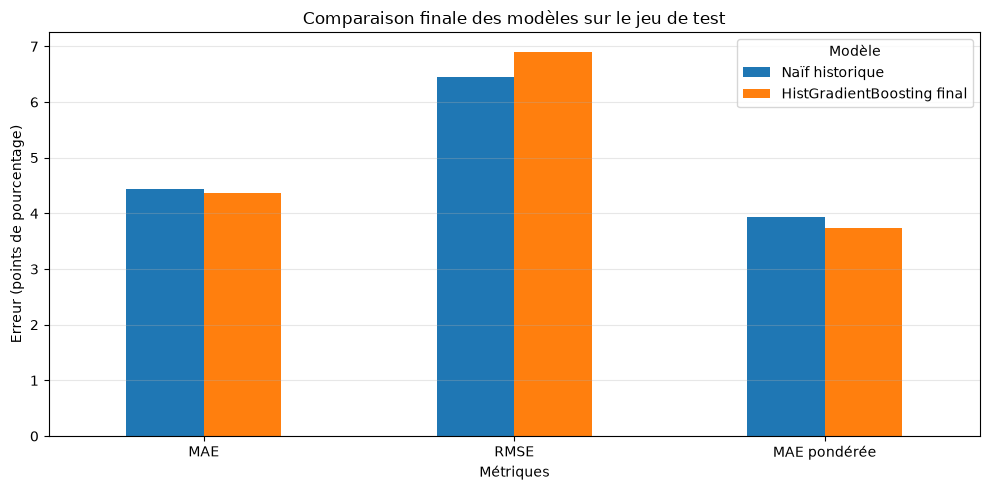

In [72]:

import matplotlib.pyplot as plt

# Convertir les erreurs en points de pourcentage.
scores_test = resultats_test[
    ["mae", "rmse", "weighted_mae"]
].copy() * 100

# Renommer les métriques pour faciliter la lecture.
scores_test = scores_test.rename(
    columns={
        "mae": "MAE",
        "rmse": "RMSE",
        "weighted_mae": "MAE pondérée",
    }
)

# Afficher les erreurs des deux modèles.
ax = scores_test.T.plot(
    kind="bar",
    figsize=(10, 5),
    rot=0,
)

ax.set_title("Comparaison finale des modèles sur le jeu de test")
ax.set_xlabel("Métriques")
ax.set_ylabel("Erreur (points de pourcentage)")
ax.legend(title="Modèle")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()



#### Interprétation des résultats sur le test

Sur le jeu de test, HistGradientBoosting obtient une MAE et une MAE pondérée légèrement inférieures à celles du modèle naïf historique.

En revanche, sa RMSE est plus élevée. Cela signifie que, même si les erreurs moyennes diminuent, le modèle commet probablement certaines erreurs plus importantes.

On remarque également que les performances sont moins bonnes que sur le jeu de validation, ce qui montre que les prédictions restent difficiles sur les périodes les plus récentes.

**Le modèle supervisé apporte donc une amélioration limitée par rapport à l'historique des retards.** Ces résultats constituent notre référence pour la suite du projet, où nous chercherons à déterminer si les caractéristiques du réseau TGV permettent d'améliorer davantage les prédictions.



### Export des résultats pour la suite du projet



In [73]:

import json
from pathlib import Path

import joblib

# Retrouver la racine du projet.
racine = Path.cwd()
if racine.name == "notebooks":
    racine = racine.parent

# Créer les dossiers pour enregistrer nos résultats.
dossier_resultats = racine / "data" / "processed" / "ml"
dossier_modeles = racine / "models"

dossier_resultats.mkdir(parents=True, exist_ok=True)
dossier_modeles.mkdir(parents=True, exist_ok=True)

# Conserver les informations utiles pour analyser les prédictions.
predictions_export = test[
    [
        "date",
        "service",
        "departure",
        "arrival",
        "circulated",
        "delay_rate_15",
    ]
].copy()

# Ajouter les prédictions de nos deux modèles.
predictions_export["prediction_naive"] = naive_test
predictions_export["prediction_ml"] = predictions_test

# Calculer les erreurs absolues de chaque modèle.
predictions_export["erreur_naive"] = (
    predictions_export["delay_rate_15"]
    - predictions_export["prediction_naive"]
).abs()

predictions_export["erreur_ml"] = (
    predictions_export["delay_rate_15"]
    - predictions_export["prediction_ml"]
).abs()

# Enregistrer les prédictions au format Parquet.
predictions_export.to_parquet(
    dossier_resultats / "baseline_predictions_test.parquet",
    index=False,
)

# Enregistrer les métriques dans un fichier JSON.
metriques_export = resultats_test.to_dict(orient="index")

with open(
    dossier_resultats / "baseline_metrics.json",
    "w",
    encoding="utf-8",
) as fichier:
    json.dump(metriques_export, fichier, indent=4)

# Sauvegarder le modèle final déjà entraîné.
joblib.dump(
    modele_final,
    dossier_modeles / "baseline_model.joblib",
)

print("Prédictions :", len(predictions_export), "observations")


Prédictions : 1857 observations


Le prochain notebook portera sur du machine learning non supervisé en l'occurence avec des algorithmes de clustering.
Nous reprendrons les resultats de cette baseline pour les comparer avec nous autres recherches.